# Can we predict BatChat's favorite Batman stories?

*Undone* ranks **47th** among BatChat's 740 Batman stories. Two models put it near **490th**. They know who made it and when it appeared. They don't know how a silent comic about grief reads.

Can names and dates predict the hosts' taste? Do plot summaries help? And what can we learn from the stories the models get wrong?

We'll start with a simple guess, test a few improvements, and inspect the misses. **Rank 1 is best.**

New to the dataset? Start with [the writers, years, and villains](2.0-batchat-the-art-of-gotham.ipynb). For reader and critic ratings, see [BatChat versus the crowd](3.0-batchat-versus-the-crowd.ipynb).

*Part of [BatRank](https://github.com/ddofer/BatRank), by [Dan Ofer](https://scholar.google.com/citations?user=uDx2ItYAAAAJ). Rankings: [Matt Lazorwitz and Will Nevin's BatChat](https://comicsxf.com/batchat-rankings/). Snapshot: October 21, 2026.*

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

candidates = [Path.cwd(), Path.cwd().parent]
candidates += [p.parents[2] for p in Path('/kaggle/input').glob('**/data/processed/stories.csv')]
DATA_ROOT = next(p for p in candidates if (p/'data/processed/stories.csv').exists())
sys.path.insert(0, str(DATA_ROOT))
from scripts.analysis import (load_data, split_set, grouped_folds, feature_frame, regression,
    fit_oof, model_summary, bootstrap_gain, block_importance, creator_table, save_figure,
    COLORS, ROLES, BIBLIOGRAPHY, CRAFT, CAST, AWARDS, AWARD_CONTROLS)
ROOT, REPORT, s, issues = load_data()
N = len(s)
s['preference'] = 1-s.rank_percentile
print(f'{N:,} ranked entries · {len(issues):,} issue references · snapshot {s.snapshot_date.iloc[0]}')


740 ranked entries · 2,434 issue references · snapshot 2026-10-21


## 1. Can we beat guessing the middle?

Each row is one story. We'll predict its place on the list using publication dates and creator names, then add characters, changes of creative team, and earlier awards.

The simplest prediction is the average rank in the training set. We measure error in **rank places**: predicting #200 for a story at #100 misses by 100 places. Lower error is better.

<details><summary>What the ranks and creator fields mean</summary>

We use page order as `rank`, keeping repeated labels from the website in `source_rank`. The `narrative_*` fields identify the people who made the selected story. Other fields include contributors to the whole issue, including unrelated backups. See the [data dictionary](../references/data_dictionary.md).

Rank gaps don't measure strength of preference. A gap of 100 places means the same error everywhere on the list, even though the hosts may feel very differently about those gaps. Ordering correlations are also saved in the reports.

</details>

In [2]:
fields = ['writers','narrative_writers','narrative_colorists','featured_entity_ids',
          'antagonists_entity_ids','collection_urls','publication_age_year_proxy',
          'cover_age_year_proxy','gcd_narrative_page_count']
coverage = s[fields].notna().sum().rename('entries_with_value').to_frame()
coverage['percent'] = coverage.entries_with_value/N*100
coverage.to_csv(REPORT/"model_data_coverage.csv")

Each prediction comes from a model that hasn't seen that story. We also keep overlapping issues and podcast episodes together. Otherwise, training on one part of an arc could make predicting another part suspiciously easy.

Sharing an episode doesn't mean sharing a rank. One Halloween episode includes *Red Rain* (**#6**) and *Superman and Batman vs. Vampires and Werewolves* (**#732**).

<details><summary>Models and validation</summary>

The same five folds are used throughout this comparison. They contain 231 connected episode/issue groups; the largest has 13 stories. Missing-value replacements and vocabularies are fitted using training data only.

Ridge regression uses a fixed penalty of 20. The random forest uses 240 trees. Award counts exclude same-year prizes and use log1p; those comparisons also control for team size and observation window.

Titles, plots, outside ratings, and the small page-count sample are excluded here.

</details>

231 connected groups; largest 13 entries
Every fold keeps both shared issues and episode companions together.


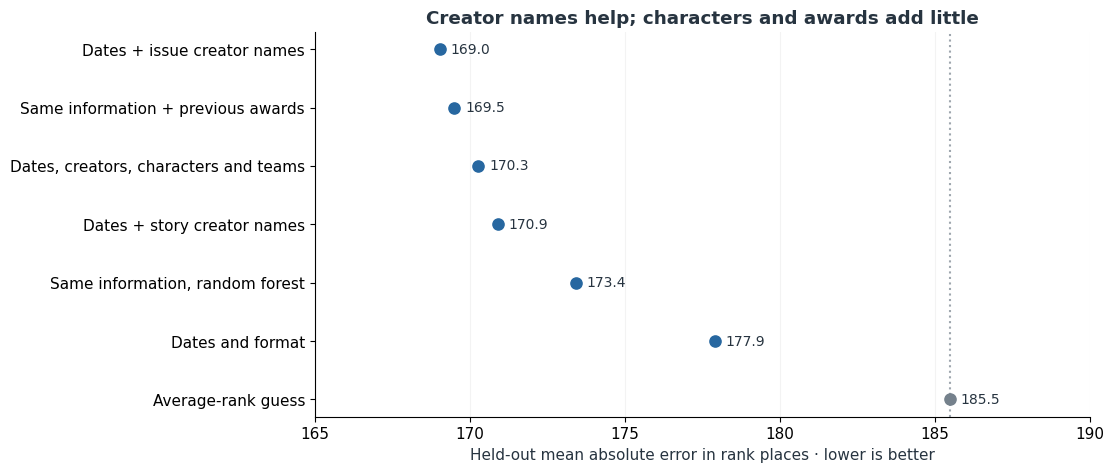

In [3]:
from sklearn.dummy import DummyRegressor
X=feature_frame(s)
y=s['rank'].to_numpy(dtype=float)
assert not {'rank','rank_percentile','source_rank','title','story_id'} & set(X)
context=BIBLIOGRAPHY+CRAFT+AWARD_CONTROLS
narrative_roles=['narrative_'+r for r in ROLES]
models={
    'Mean baseline':DummyRegressor(),
    'Era / format':regression(BIBLIOGRAPHY),
    'Whole-issue credits':regression(BIBLIOGRAPHY+AWARD_CONTROLS,ROLES),
    'Narrative credits':regression(BIBLIOGRAPHY+AWARD_CONTROLS,narrative_roles),
    'Cast + craft':regression(context,narrative_roles+CAST),
    'Cast + craft + prior awards':regression(context+AWARDS,narrative_roles+CAST),
    'Random forest: expanded':regression(context+AWARDS,narrative_roles+CAST,forest=True),
}
groups,folds=grouped_folds(s,issues)
fold_number=np.empty(N,dtype=int)
for k,(_,test) in enumerate(folds):fold_number[test]=k
pd.DataFrame({'story_id':s.story_id,'group':groups,'fold':fold_number}).to_csv(REPORT/'validation_folds.csv',index=False)
print(f'{len(set(groups))} connected groups; largest {pd.Series(groups).value_counts().max()} entries')
print('Every fold keeps both shared issues and episode companions together.')
oof,fitted,fold_metrics=fit_oof(models,X,y,folds)
summary=model_summary(y,oof)
summary=summary.drop(columns='Spearman').merge(
    fold_metrics.groupby('model')[['Spearman','Kendall_tau']].mean().reset_index(),on='model')
summary=summary.rename(columns={'Spearman':'mean_fold_Spearman','Kendall_tau':'mean_fold_Kendall'})
summary.to_csv(REPORT/'model_summary.csv',index=False)
fold_metrics.to_csv(REPORT/'cv_metrics.csv',index=False)

model_labels={'Mean baseline':'Average-rank guess','Era / format':'Dates and format',
    'Whole-issue credits':'Dates + issue creator names','Narrative credits':'Dates + story creator names',
    'Cast + craft':'Dates, creators, characters and teams','Cast + craft + prior awards':'Same information + previous awards',
    'Random forest: expanded':'Same information, random forest'}
fig,ax=plt.subplots(figsize=(10,5))
shown=summary.set_index('model').MAE_rank_places.sort_values()
for pos,(name,value) in enumerate(shown.items()):
    color=COLORS['grey'] if name=='Mean baseline' else COLORS['blue']
    ax.scatter(value,pos,color=color,s=65,zorder=3)
    ax.text(value+.35,pos,f'{value:.1f}',va='center',fontsize=10)
ax.axvline(shown['Mean baseline'],ls=':',color=COLORS['grey'],alpha=.7)
ax.set(yticks=range(len(shown)),yticklabels=[model_labels[x] for x in shown.index],xlim=(165,190),
       xlabel='Held-out mean absolute error in rank places · lower is better',
       title='Creator names help; characters and awards add little')
ax.invert_yaxis();ax.xaxis.grid(True,alpha=.15);ax.set_axisbelow(True)
save_figure(fig,REPORT,'model-benchmarks')

Creator names and publication details reduce the average miss from **185.5 to 169.0 places**. That's about **9% less error**, but still a large miss on a 740-story list.

More information doesn't buy much. Characters, team changes, and awards leave the predictions at roughly the same accuracy. Even restricting the names to people who made the selected story doesn't improve the result. Names from unrelated backups may help identify an era or series.

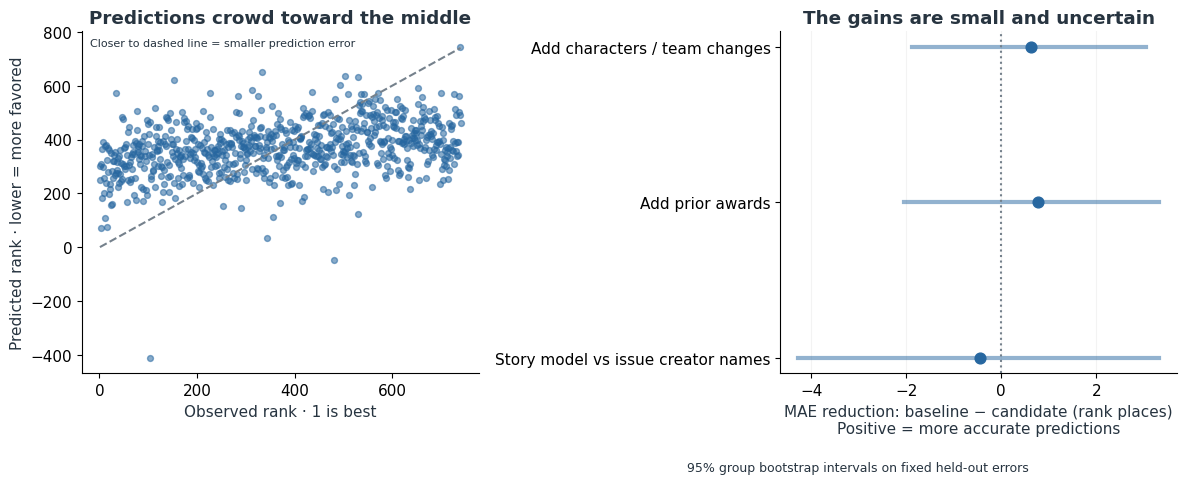

In [4]:
comparisons=[('Narrative credits','Cast + craft'),('Cast + craft','Cast + craft + prior awards'),
             ('Whole-issue credits','Cast + craft + prior awards')]
gains=pd.DataFrame([{'baseline':a,'candidate':b,**bootstrap_gain(y,oof[a],oof[b],groups)} for a,b in comparisons])

gains.to_csv(REPORT/'feature_block_gains.csv',index=False)
full='Cast + craft + prior awards'
fig,axes=plt.subplots(1,2,figsize=(12,4.6))
axes[0].scatter(y,oof[full],s=18,alpha=.55,color=COLORS['blue'])
axes[0].plot([1,N],[1,N],ls='--',color=COLORS['grey'])
axes[0].text(.02,.98,'Closer to dashed line = smaller prediction error',transform=axes[0].transAxes,va='top',fontsize=8)
axes[0].set(xlabel='Observed rank · 1 is best',ylabel='Predicted rank · lower = more favored',title='Predictions crowd toward the middle')
for pos,(_,row) in enumerate(gains.iterrows()):
    axes[1].plot([row.ci_low,row.ci_high],[pos,pos],lw=3,color=COLORS['blue'],alpha=.5)
    axes[1].scatter(row.gain_rank_places,pos,s=60,color=COLORS['blue'])
axes[1].axvline(0,ls=':',color=COLORS['grey'])
axes[1].set(yticks=range(3),yticklabels=['Add characters / team changes','Add prior awards','Story model vs issue creator names'],
            xlabel='MAE reduction: baseline − candidate (rank places)\nPositive = more accurate predictions',
            title='The gains are small and uncertain')
axes[1].invert_yaxis();axes[1].xaxis.grid(True,alpha=.15);axes[1].set_axisbelow(True)
fig.text(.72,-.04,'95% group bootstrap intervals on fixed held-out errors',ha='center',fontsize=9)
fig.tight_layout();save_figure(fig,REPORT,'model-calibration')

The model also avoids strong opinions. Favorites get pulled down toward the middle; low-ranked stories get pulled up. The dashed line shows where accurate predictions would fall.

Adding characters and team details saves **0.62 places** on average. Adding earlier awards saves another **0.78**. Both uncertainty intervals cross zero. These additions haven't earned a claim of better predictions.

<details><summary>Uncertainty and feature importance</summary>

Intervals resample saved prediction errors by connected episode/issue group. They don't include uncertainty from refitting models or choosing analyses.

The model with characters, team details, and awards is 0.46 places worse on average than the model using all issue contributors. The interval spans 4.27 places worse to 3.31 better.

Permutation results and Ridge coefficients are saved in `reports/`. Shuffling dates, counts, and data-completeness fields hurts predictions most. Creator names overlap as clues to a particular run, so their individual importance cannot tell us whose work made the comic good.

</details>

In [5]:
blocks={
    'Bibliography / scope controls':BIBLIOGRAPHY+AWARD_CONTROLS,
    'Writers':['narrative_writers'],
    'Pencils / inks':['narrative_pencilers','narrative_inkers'],
    'Color / lettering / editing':['narrative_colorists','narrative_letterers','narrative_editors'],
    'Cast identities':CAST,
    'Craft / coverage':CRAFT,
    'Prior personal awards':AWARDS,
}
importance=block_importance(fitted[full],X,y,folds,blocks,repeats=5)
importance.to_csv(REPORT/'permutation_importance.csv',index=False)
imp=importance.groupby(['fold','block']).MAE_increase_rank_places.mean().groupby('block').agg(['mean','std']).sort_values('mean')

coefficients=[]
for fold,model in enumerate(fitted[full]):
    coefficients.extend({'fold':fold,'feature':name,'coefficient':value} for name,value in zip(
        model[0].get_feature_names_out(),model[-1].coef_))
coef=pd.DataFrame(coefficients).groupby('feature').coefficient.agg(['mean','std','count'])
coef.to_csv(REPORT/'ridge_coefficients.csv')
creators=coef[coef.index.str.startswith(('narrative_writers__','narrative_pencilers__')) & coef['count'].ge(4)]



## 2. What happens with unfamiliar artists or later episodes?

Ordinary validation can put the same artist in training and testing. What happens when the model hasn't seen that artist's work?

We hold out the five most frequent pencilers, one at a time. Each time, we remove all their work from training, including stories where they had another role. Connected episodes and issues leave too.

In [6]:
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error,r2_score

dates=pd.to_datetime(s.discussion_date)
cutoff=dates.sort_values().iloc[int(.8*N)]
test=np.flatnonzero(dates.ge(cutoff));train=np.flatnonzero(dates.lt(cutoff)&~pd.Series(groups).isin(groups[test]))
assert set(groups[train]).isdisjoint(groups[test])
model=clone(models[full]).fit(X.iloc[train],y[train]);prediction=model.predict(X.iloc[test])
time_result={'cutoff':str(cutoff.date()),'n_train':len(train),'n_test':len(test),
             'model_MAE':mean_absolute_error(y[test],prediction),'mean_baseline_MAE':mean_absolute_error(y[test],np.repeat(y[train].mean(),len(test))),
             'R2':r2_score(y[test],prediction)}
(REPORT/'chronological_holdout.json').write_text(json.dumps(time_result,indent=2))

artist_counts=s.narrative_pencilers.map(split_set).explode().value_counts().head(5)
heldout=[]
for artist,n in artist_counts.items():
    test_mask=s.narrative_pencilers.map(lambda names:artist in split_set(names))
    any_role=s[narrative_roles].apply(lambda row:any(artist in split_set(value) for value in row),axis=1)
    test=np.flatnonzero(test_mask)
    train=np.flatnonzero(~any_role & ~pd.Series(groups).isin(groups[test]))
    assert not any_role.iloc[train].any() and set(groups[train]).isdisjoint(groups[test])
    m=clone(models[full]).fit(X.iloc[train],y[train]);pred=m.predict(X.iloc[test])
    heldout.append({'held_out_creator':artist,'n_test':len(test),'MAE':mean_absolute_error(y[test],pred),
                    'baseline_MAE':mean_absolute_error(y[test],np.repeat(y[train].mean(),len(test)))})
heldout=pd.DataFrame(heldout)
print('MAE = average absolute miss in rank places; lower means more accurate predictions.')
display(heldout.rename(columns={'held_out_creator':'Artist held out','n_test':'Stories','MAE':'Model MAE · lower = better','baseline_MAE':'Mean-guess MAE · lower = better'}).round(1));heldout.to_csv(REPORT/'creator_holdouts.csv',index=False)

MAE = average absolute miss in rank places; lower means more accurate predictions.


,Artist held out,Stories,Model MAE · lower = better,Mean-guess MAE · lower = better
0,Jim Aparo,24,153.9,169.3
1,Bob Kane,20,125.6,190.5
2,Norm Breyfogle,19,135.2,139.5
3,Neal Adams,16,150.3,173.2
4,Kelley Jones,16,238.4,212.0


The answer depends on the artist. Jim Aparo's stories beat the average-rank guess; Kelley Jones's do worse. Familiar writers and characters remain available as clues, but they don't always help enough.

A second test trains on earlier discussions and predicts the last 149 stories discussed. Error is **140.9 places**, compared with **143.6** for the simple guess. The apparent improvement over our first experiment is mostly an easier test set: both models make smaller errors.

We gain just **2.7 places** over that baseline. I wouldn't use this to forecast the next episode.

<details><summary>What the date test can establish</summary>

The cutoff is August 7, 2025. After removing overlapping groups, 573 stories remain for training. R² on the 149 test stories is −0.028.

These are predictions of today's ranks, split by discussion date. We don't have a historical ranking after every episode, so this doesn't test whether early choices need reranking. Artist holdouts were selected by frequency before inspecting their errors.

</details>

## 3. The interesting misses

Back to *Undone*. Ridge predicts **#485**; the forest predicts **#491**. BatChat puts it at **#47**.

Below are other stories where both models miss in the same direction. These are good examples to discuss, though the tendency to predict middling ranks will exaggerate some disagreements.

<details><summary>How these examples were selected</summary>

We exclude unresolved issue and story matches. Examples are ordered by the gap between BatChat's rank and the ordering of held-out Ridge predictions. The forest must disagree in the same direction.

The tables show raw predicted ranks. Sorting predictions across five fitted models can mix differences in their prediction levels, so this is an exploratory selection, not a replacement ranking.

</details>

In [7]:
predictions=s[['story_id','title','rank','discussion_date','substory_attribution_coverage','metadata_complete']].copy()
predictions['predicted_rank']=oof[full]
predictions['predicted_order']=pd.Series(oof[full]).rank(method='average')
predictions['forest_prediction']=oof['Random forest: expanded']
predictions['actual_minus_prediction']=predictions['rank']-predictions.predicted_rank
predictions['ordering_gap']=predictions['rank']-predictions.predicted_order
predictions['forest_predicted_order']=pd.Series(oof['Random forest: expanded']).rank(method='average')
predictions['model_agreement']=np.sign(predictions.ordering_gap)==np.sign(y-predictions.forest_predicted_order)
predictions['fold']=fold_number
predictions.to_csv(REPORT/'reranking_candidates.csv',index=False)
clean=predictions[predictions.metadata_complete & predictions.substory_attribution_coverage.eq(1) & predictions.model_agreement]
cols=['title','rank','predicted_rank','forest_prediction']
labels={'title':'Story','rank':'BatChat rank · 1 = best','predicted_rank':'Ridge rank · lower = more favored','forest_prediction':'Forest rank · lower = more favored'}
print('Hosts liked these more than their metadata suggested:')
display(clean.nsmallest(5,'ordering_gap')[cols].rename(columns=labels).round(0))
print('Hosts liked these less than their metadata suggested:')
display(clean.nlargest(5,'ordering_gap')[cols].rename(columns=labels).round(0))

watch=[]
for row in s.itertuples():
    for name in split_set(row.creator_watch_names):
        roles=[role for role in ROLES+['executive_editors'] if name in split_set(getattr(row,role))]
        narrative=[role for role in narrative_roles if name in split_set(getattr(row,role))]
        watch.append({'story_id':row.story_id,'creator':name,'whole_issue_roles':'|'.join(roles),
                      'narrative_credit_hit':bool(narrative)})
watch=pd.DataFrame(watch)

watch.to_csv(REPORT/'creator_watch_role_audit.csv',index=False)
assert len(predictions)==N and np.isfinite(predictions.predicted_rank).all()

Hosts liked these more than their metadata suggested:


,Story,BatChat rank · 1 = best,Ridge rank · lower = more favored,Forest rank · lower = more favored
32,The Dark Knight Returns: The Last Crusade,33,572.0,368.0
46,Undone,47,485.0,491.0
76,Batman: Eternal Part 1,77,504.0,355.0
47,Night of the Stalker,48,476.0,463.0
113,The Joker/ The Joker Returns,114,518.0,519.0


Hosts liked these less than their metadata suggested:


,Story,BatChat rank · 1 = best,Ridge rank · lower = more favored,Forest rank · lower = more favored
696,Knightquest: The Search,697,234.0,278.0
714,Batman/Houdini: The Devil’s Workshop,715,253.0,280.0
702,The Wedding,703,252.0,363.0
635,Demons,636,215.0,198.0
654,Batman: Harley & Ivy #1-3,655,250.0,276.0


*The Last Crusade* and *Night of the Stalker* join *Undone* among the unexpected favorites. *The Wedding* goes the other way. Knowing the team behind a comic leaves plenty unexplained.

The next experiment gives the model something about what happens in the story.

<a id="does-knowing-the-plot-help"></a>
<a id="6.-Does-knowing-the-plot-help?"></a>

## 4. Does knowing the plot help?

We have roughly **700,000 words of wiki plot summaries**. Let's turn them into weighted bags of words using TF-IDF. A word gets more weight when it recurs in one summary and less when it appears across many summaries.

This captures names and subjects. It loses word order, pacing, and the pictures.

We compare a model using words alone with one that already knows the creators, dates, characters, and awards. The latter also gets summary availability, completeness, and length. That helps distinguish useful vocabulary from the fact that some comics are documented more thoroughly.

<details><summary>Text coverage and validation</summary>

There are 1,711 available synopsis fields containing 703,219 words. Of 740 stories, 587 have some text and 481 have every selected summary plus a complete issue list. No length cap is applied.

The audit removed a critical-reception section from *Arkham Asylum* and contributor boilerplate from two anthology summaries. Duplicate text is counted once per story.

Shared source narratives and identical normalized text are grouped with episodes and issues, leaving 231 groups. All 740 stories remain in the comparison, including those without text.

Vocabulary and IDF are fitted within training splits. Each outer fold selects Ridge's penalty from 1, 10, and 100 using three inner grouped folds. These tuned models have their own baseline; the earlier fixed-penalty result is a separate experiment.

</details>

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV,GroupKFold
from sklearn.pipeline import make_pipeline
from scripts.analysis import plot_documents

texts=pd.read_csv(ROOT/'data/processed/story_texts.csv')
documents=plot_documents(s,texts)
X=feature_frame(s).join(documents.drop(columns='story_id'))
y=s['rank'].to_numpy(dtype=float)
text_groups,text_folds=grouped_folds(s,issues,texts=texts)
plot_controls=['plot_available','plot_complete','plot_fraction','log_plot_words','log_plot_units']
numeric=BIBLIOGRAPHY+CRAFT+AWARDS+AWARD_CONTROLS
roles=['narrative_'+r for r in ROLES]+CAST
# The vocabulary and inverse-document frequencies are learned inside each training split.
def bag_of_words():
    return TfidfVectorizer(stop_words='english',min_df=3,max_df=.95,max_features=12000,
                          ngram_range=(1,1),sublinear_tf=True,strip_accents='unicode')
control=regression(numeric+plot_controls,roles)
with_words=clone(control)
with_words[0].transformers.append(('plot',bag_of_words(),'plot_text'))
words_only=make_pipeline(ColumnTransformer([('plot',bag_of_words(),'plot_text')]),Ridge(solver='lsqr'))
text_models={'Mean guess':DummyRegressor(), 'Plot words only':words_only,
             'Credits + text coverage':control,'Credits + text coverage + words':with_words}
text_predictions={name:np.empty(len(s)) for name in text_models}
text_fitted={name:[] for name in text_models}
choices=[]
for fold,(train,test) in enumerate(text_folds):
    inner=list(GroupKFold(n_splits=3).split(X.iloc[train],groups=text_groups[train]))
    for name,template in text_models.items():
        if name=='Mean guess':
            model=clone(template).fit(X.iloc[train],y[train]);alpha=None
        else:
            search=GridSearchCV(template,{'ridge__alpha':[1.,10.,100.]},cv=inner,
                                scoring='neg_mean_absolute_error',n_jobs=1,error_score='raise')
            search.fit(X.iloc[train],y[train]);model=search.best_estimator_;alpha=search.best_params_['ridge__alpha']
        text_predictions[name][test]=model.predict(X.iloc[test]);text_fitted[name].append(model)
        choices.append({'fold':fold,'model':name,'alpha':alpha,'test_size':len(test)})
assert all(np.isfinite(p).all() for p in text_predictions.values())
cohorts={'All stories':np.ones(len(s),dtype=bool),'Some plot text':documents.plot_available.eq(1).to_numpy(),
         'All selected plots present':documents.plot_complete.eq(1).to_numpy()}
text_scores=[];text_gains=[]
for label,mask in cohorts.items():
    for name,prediction in text_predictions.items():
        text_scores.append({'cohort':label,'n':int(mask.sum()),'model':name,
                            'MAE_rank_places':mean_absolute_error(y[mask],prediction[mask])})
    text_gains.append({'cohort':label,'n':int(mask.sum()),**bootstrap_gain(y[mask],
        text_predictions['Credits + text coverage'][mask],text_predictions['Credits + text coverage + words'][mask],text_groups[mask])})
text_scores=pd.DataFrame(text_scores);text_gains=pd.DataFrame(text_gains)
text_scores.to_csv(REPORT/'plot_model_scores.csv',index=False)
text_gains.to_csv(REPORT/'plot_model_gains.csv',index=False)
pd.DataFrame(choices).to_csv(REPORT/'plot_model_tuning.csv',index=False)
pd.DataFrame({'story_id':s.story_id,'rank':y,'group':text_groups,**text_predictions}).to_csv(REPORT/'plot_model_predictions.csv',index=False)
display(text_scores.assign(model=text_scores.model.replace({'Credits + text coverage':'Names, dates, characters, awards + text coverage','Credits + text coverage + words':'Same information + plot words'}))[text_scores.cohort.eq('All stories')][['model','MAE_rank_places']].rename(columns={'model':'Information given to the model','MAE_rank_places':'MAE in rank places · lower = better'}).round(1))

# Keep word coefficients available for inspection; they are associations in wiki summaries.
word_coefficients=[]
for fold,model in enumerate(text_fitted['Plot words only']):
    word_coefficients.extend({'fold':fold,'term':name.removeprefix('plot__'),'coefficient':value}
        for name,value in zip(model[0].get_feature_names_out(),model[-1].coef_))
word_coefficients=pd.DataFrame(word_coefficients)
word_coefficients.to_csv(REPORT/'plot_word_coefficients.csv',index=False)


,Information given to the model,MAE in rank places · lower = better
0,Mean guess,185.5
1,Plot words only,179.2
2,"Names, dates, characters, awards + text coverage",170.9
3,Same information + plot words,170.6


Words alone beat guessing the middle: **179.2 versus 185.5 places** of error.

Once names, dates, and the other information are available, the words add almost nothing. Error falls from about **170.9 to 170.6 places**. The gain is **0.31 places**, with an uncertainty interval crossing zero.

Among stories with complete summaries, the gain is still less than one place. The bars below resample saved errors without refitting.

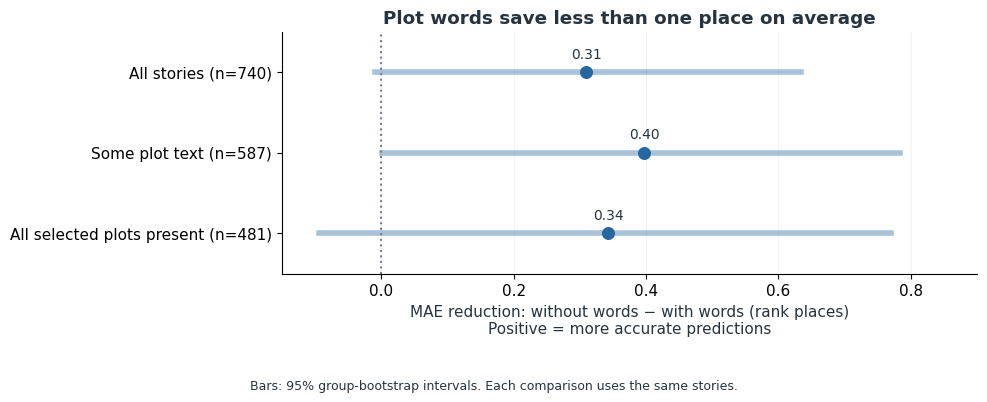

In [9]:
fig,ax=plt.subplots(figsize=(10,4))
for pos,(_,row) in enumerate(text_gains.iterrows()):
    ax.plot([row.ci_low,row.ci_high],[pos,pos],color=COLORS['blue'],lw=4,alpha=.4)
    ax.scatter(row.gain_rank_places,pos,color=COLORS['blue'],s=70,zorder=3)
    ax.annotate(f'{row.gain_rank_places:.2f}',(row.gain_rank_places,pos),xytext=(0,10),
                textcoords='offset points',ha='center',fontsize=10)
ax.axvline(0,color=COLORS['grey'],ls=':')
ax.set(yticks=range(len(text_gains)),
       yticklabels=[f'{r.cohort} (n={r.n})' for r in text_gains.itertuples()],
       xlabel='MAE reduction: without words − with words (rank places)\nPositive = more accurate predictions',
       title='Plot words save less than one place on average',xlim=(-.15,.9),ylim=(2.5,-.5))
ax.xaxis.grid(True,alpha=.15);ax.set_axisbelow(True)
fig.text(.5,.01,'Bars: 95% group-bootstrap intervals. Each comparison uses the same stories.',ha='center',fontsize=9)
fig.tight_layout(rect=(0,.1,1,1));save_figure(fig,REPORT,'model-plot-gain')

## 5. Better for finding related stories?

Prediction isn't the only use for these summaries. What happens if we ask for the closest match to *Undone*, *Ego*, and *The Clown at Midnight*?

These three examples come from [the storytelling discussion](2.0-batchat-the-art-of-gotham.ipynb). TF-IDF chooses each neighbor, requiring complete summaries and excluding the same episode/issue group. The chart shows the three words contributing most to each match.

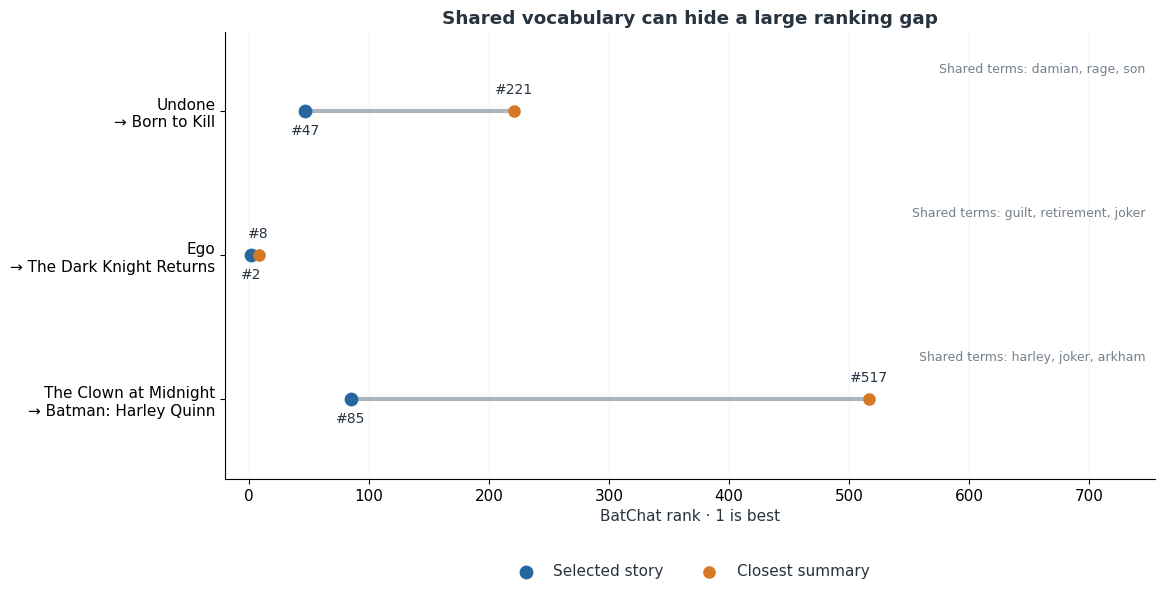

In [10]:
from sklearn.metrics.pairwise import cosine_similarity
available=np.flatnonzero(documents.plot_complete.eq(1))
retrieval=TfidfVectorizer(stop_words='english',min_df=3,max_df=.95,max_features=12000,ngram_range=(1,1),sublinear_tf=True,strip_accents='unicode')
vectors=retrieval.fit_transform(documents.plot_text.iloc[available]);similarity=cosine_similarity(vectors)
lookup={idx:pos for pos,idx in enumerate(available)};records=[]
for title in ['Undone','Ego','The Clown at Midnight']:
 idx=s.index[s.title.eq(title)][0];assert idx in lookup
 pos=lookup[idx];scores=similarity[pos].copy();scores[text_groups[available]==text_groups[idx]]=-1
 match=int(scores.argmax());other=available[match]
 overlap=vectors[pos].multiply(vectors[match]).toarray().ravel()
 terms=retrieval.get_feature_names_out()[np.argsort(-overlap)[:3]]
 records.append({'anchor':title,'anchor_rank':int(s['rank'].iloc[idx]),'neighbor':s.title.iloc[other],
 'neighbor_rank':int(s['rank'].iloc[other]),'cosine_similarity':float(scores[match]),'shared_terms':', '.join(terms),
 'anchor_id':s.story_id.iloc[idx],'neighbor_id':s.story_id.iloc[other]})
neighbors=pd.DataFrame(records);neighbors.to_csv(REPORT/'plot_neighbors.csv',index=False)


from textwrap import fill
fig,ax=plt.subplots(figsize=(12,5.8))
for pos,row in enumerate(neighbors.itertuples()):
    ax.plot([row.anchor_rank,row.neighbor_rank],[pos,pos],color='#ABB5BD',lw=3,zorder=1)
    ax.scatter(row.anchor_rank,pos,color=COLORS['blue'],s=80,zorder=3,label='Selected story' if pos==0 else None)
    ax.scatter(row.neighbor_rank,pos,color=COLORS['orange'],s=65,zorder=3,label='Closest summary' if pos==0 else None)
    for rank,offset in [(row.anchor_rank,-17),(row.neighbor_rank,13)]:
        ax.annotate(f'#{rank}',(rank,pos),xytext=(0,offset),textcoords='offset points',ha='center',fontsize=10)
    ax.text(.99,pos-.27,'Shared terms: '+row.shared_terms,transform=ax.get_yaxis_transform(),
            ha='right',fontsize=9,color=COLORS['grey'])
ax.set(yticks=range(len(neighbors)),
       yticklabels=[fill(r.anchor,27)+'\n→ '+fill(r.neighbor,27) for r in neighbors.itertuples()],
       xlabel='BatChat rank · 1 is best',title='Shared vocabulary can hide a large ranking gap',
       xlim=(-20,N+15),ylim=(-.55,len(neighbors)-.45))
ax.invert_yaxis();ax.xaxis.grid(True,alpha=.15);ax.set_axisbelow(True)
ax.legend(loc='upper center',bbox_to_anchor=(.5,-.16),ncol=2,frameon=False)
save_figure(fig,REPORT,'model-plot-neighbors')


*Undone* finds *Born to Kill* through **Damian, rage, and son**. Their ranks are **#47 and #221**. *The Clown at Midnight* finds *Batman: Harley Quinn* through **Harley, Joker, and Arkham**: **#85 and #517**.

Shared vocabulary sometimes finds two favorites. **Guilt, retirement, and Joker** connect *Ego* (**#2**) with *The Dark Knight Returns* (**#8**).

Creator names and dates predict a little of BatChat's taste. These plot words add almost nothing. They are more useful for finding comics to compare: common characters and concerns can lead to very different reading experiences.

I'd put *Undone* beside *Born to Kill* and look at how each handles Damian's anger. The shared words give us a reason to read them together. The ranking gap gives us something to argue about.

Continue with [the EDA](2.0-batchat-the-art-of-gotham.ipynb) or [reader and critic disagreements](3.0-batchat-versus-the-crowd.ipynb).

**Files:** Scores, predictions, and summary matches are saved in `reports/`. [Data dictionary](../references/data_dictionary.md) · [Kaggle setup](../references/kaggle-sharing.md).